# ChiliEdgeNet — Cross-dataset Evaluation (LOCAL, khong dung Kaggle)

Chay checkpoint da tai ve local (`kq/model/`), KHONG train lai, chi test tren dataset cross-check.
Checkpoint C14 seed 46 duoc train voi 5 lop, vi vay kien truc model van phai giu du 5 dau ra.

`CROSS_DIR = D:\ds\test` hien co 4 lop: `healthy`, `leaf_curl`, `leaf_spot`, `yellow_leaf`.
Tap test khong co anh `anthracnose`; notebook bo lop nay khoi metric theo lop, nhung cac du doan
nham sang `anthracnose` van duoc tinh la sai trong accuracy va confusion matrix.


In [10]:
import os, glob
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from torchinfo import summary as torchinfo_summary
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42); torch.cuda.manual_seed_all(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
N_GPUS = torch.cuda.device_count()
print(f'Device: {DEVICE} | GPUs: {N_GPUS}')

Device: cpu | GPUs: 0


In [11]:
# ===== Config (LOCAL) =====
CKPT_DIR = r'E:\UIT\study\claude\learn-claude\papers\05_RTR-Lite-MobileNet\outputs\build_conference\kq\model'
CKPT_NAME_CANDIDATES = ['c14_s2_seed42.pth', 'c14_s1_seed42.pth']  # uu tien S2 (domain-robust)

CROSS_DIR = r'D:\ds\test'   # root chua 4 folder lop; hien khong test anthracnose

IMG_SIZE, BATCH_SIZE = 224, 32
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
BACKBONE_CUT = 14  # khop voi checkpoint c14_* (671K params, ban de xuat)
TF_EMBED_DIM, TF_DEPTH = 128, 1
TF_HEADS, TF_KV_HEADS = 4, 2
TF_MLP_RATIO, TF_DROP, TF_ROPE_BASE = 2.0, 0.1, 100.0

In [12]:
# ChiliEdgeNet - copy y het NB train de load dung checkpoint
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__(); self.eps, self.weight = eps, nn.Parameter(torch.ones(dim))
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def build_axial_rope(gh, gw, head_dim, base=100.0):
    d = head_dim // 2
    inv = 1.0 / (base ** (torch.arange(0, d, 2).float() / d))
    gy = torch.arange(gh).float().view(gh, 1).expand(gh, gw).reshape(-1)
    gx = torch.arange(gw).float().view(1, gw).expand(gh, gw).reshape(-1)
    ey = torch.cat([torch.outer(gy, inv)] * 2, dim=-1)
    ex = torch.cat([torch.outer(gx, inv)] * 2, dim=-1)
    return ey.cos()[None,None], ey.sin()[None,None], ex.cos()[None,None], ex.sin()[None,None]

def _rot_half(x):
    x1, x2 = x[..., :x.shape[-1]//2], x[..., x.shape[-1]//2:]
    return torch.cat((-x2, x1), dim=-1)

def apply_rope2d(t, cy, sy, cx, sx):
    d = t.shape[-1] // 2
    ty, tx = t[..., :d], t[..., d:]
    ty = ty * cy + _rot_half(ty) * sy
    tx = tx * cx + _rot_half(tx) * sx
    return torch.cat([ty, tx], dim=-1)

class GroupedQueryAttention(nn.Module):
    def __init__(self, dim, nh, nkv, dropout=0.0):
        super().__init__()
        self.nh, self.nkv, self.hd = nh, nkv, dim // nh
        self.groups, self.scale = nh // nkv, (dim // nh) ** -0.5
        self.q = nn.Linear(dim, nh * self.hd, bias=False)
        self.k = nn.Linear(dim, nkv * self.hd, bias=False)
        self.v = nn.Linear(dim, nkv * self.hd, bias=False)
        self.o = nn.Linear(nh * self.hd, dim, bias=False)
        self.ad, self.pd = nn.Dropout(dropout), nn.Dropout(dropout)
    def forward(self, x, rope):
        B, N, _ = x.shape; cy, sy, cx, sx = rope
        q = self.q(x).view(B, N, self.nh, self.hd).transpose(1, 2)
        k = self.k(x).view(B, N, self.nkv, self.hd).transpose(1, 2)
        v = self.v(x).view(B, N, self.nkv, self.hd).transpose(1, 2)
        q, k = apply_rope2d(q, cy, sy, cx, sx), apply_rope2d(k, cy, sy, cx, sx)
        if self.groups > 1:
            k = k.repeat_interleave(self.groups, dim=1)
            v = v.repeat_interleave(self.groups, dim=1)
        attn = self.ad(((q @ k.transpose(-2, -1)) * self.scale).softmax(-1))
        return self.pd(self.o((attn @ v).transpose(1, 2).reshape(B, N, -1)))

class TinyLLMBlock(nn.Module):
    def __init__(self, dim, nh, nkv, mlp_ratio=2.0, dropout=0.1):
        super().__init__()
        self.n1 = RMSNorm(dim); self.attn = GroupedQueryAttention(dim, nh, nkv, dropout)
        self.n2 = RMSNorm(dim); h = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(nn.Linear(dim, h), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(h, dim), nn.Dropout(dropout))
    def forward(self, x, rope):
        x = x + self.attn(self.n1(x), rope)
        return x + self.mlp(self.n2(x))

class ChiliEdgeNet(nn.Module):
    def __init__(self, num_classes, pretrained=False, cut=BACKBONE_CUT,
                 embed_dim=TF_EMBED_DIM, depth=TF_DEPTH, heads=TF_HEADS, kv_heads=TF_KV_HEADS,
                 mlp_ratio=TF_MLP_RATIO, drop=TF_DROP, rope_base=TF_ROPE_BASE):
        super().__init__()
        w = torchvision.models.MobileNet_V2_Weights.IMAGENET1K_V1 if pretrained else None
        base = torchvision.models.mobilenet_v2(weights=w)
        self.first_conv = base.features[0]
        self.backbone = nn.Sequential(*list(base.features[1:cut]))
        with torch.no_grad():
            feat = self.backbone(self.first_conv(torch.zeros(1,3,IMG_SIZE,IMG_SIZE)))
        c_out, grid = feat.shape[1], feat.shape[2]
        self.reduce = nn.Sequential(nn.Conv2d(c_out, embed_dim, 1, bias=False),
                                    nn.BatchNorm2d(embed_dim), nn.GELU())
        self.emb_drop = nn.Dropout(drop)
        cy, sy, cx, sx = build_axial_rope(grid, grid, embed_dim // heads, base=rope_base)
        for n, b in zip(['rcy','rsy','rcx','rsx'], [cy, sy, cx, sx]):
            self.register_buffer(n, b, persistent=False)
        self.encoder = nn.ModuleList([TinyLLMBlock(embed_dim, heads, kv_heads, mlp_ratio, drop)
                                      for _ in range(depth)])
        self.norm = RMSNorm(embed_dim)
        self.drop = nn.Dropout(0.2)
        self.fc = nn.Linear(embed_dim, num_classes)
    def forward(self, x):
        x = self.backbone(self.first_conv(x))
        x = self.emb_drop(self.reduce(x).flatten(2).transpose(1, 2))
        rope = (self.rcy, self.rsy, self.rcx, self.rsx)
        for blk in self.encoder:
            x = blk(x, rope)
        return self.fc(self.drop(self.norm(x).mean(dim=1)))

In [13]:
# Tim checkpoint local va load model (chua can CROSS_DIR o buoc nay)
def _find_ckpt():
    for name in CKPT_NAME_CANDIDATES:
        p = os.path.join(CKPT_DIR, name)
        if os.path.exists(p):
            return p
    return None

CKPT_PATH = _find_ckpt()
assert CKPT_PATH, f'Khong tim thay checkpoint {CKPT_NAME_CANDIDATES} trong {CKPT_DIR}'
print('Checkpoint:', CKPT_PATH)

# Day la thu tu dau ra luc TRAIN, khong phai danh sach lop dang co trong tap test.
# Phai giu anthracnose de khop fc.weight [5, 128] cua checkpoint, du tap test hien tai khong co lop nay.
CLASS_NAMES_TRAIN = ['anthracnose', 'healthy', 'leaf_curl', 'leaf_spot', 'yellow_leaf']

checkpoint = torch.load(CKPT_PATH, map_location=DEVICE)
ckpt_num_classes = checkpoint['fc.weight'].shape[0]
assert ckpt_num_classes == len(CLASS_NAMES_TRAIN), (
    f'Checkpoint co {ckpt_num_classes} dau ra nhung CLASS_NAMES_TRAIN co {len(CLASS_NAMES_TRAIN)} lop.'
)
model = ChiliEdgeNet(ckpt_num_classes, pretrained=False).to(DEVICE)
model.load_state_dict(checkpoint, strict=True)
if N_GPUS > 1:
    model = nn.DataParallel(model)
model.eval()

_m = model.module if isinstance(model, nn.DataParallel) else model
torchinfo_summary(_m, input_size=(1, 3, IMG_SIZE, IMG_SIZE), col_names=['input_size', 'output_size', 'num_params'], depth=4, device=DEVICE)

Checkpoint: E:\UIT\study\claude\learn-claude\papers\05_RTR-Lite-MobileNet\outputs\build_conference\kq\model\c14_s2_seed42.pth


Layer (type:depth-idx)                             Input Shape               Output Shape              Param #
ChiliEdgeNet                                       [1, 3, 224, 224]          [1, 5]                    --
├─Conv2dNormActivation: 1-1                        [1, 3, 224, 224]          [1, 32, 112, 112]         --
│    └─Conv2d: 2-1                                 [1, 3, 224, 224]          [1, 32, 112, 112]         864
│    └─BatchNorm2d: 2-2                            [1, 32, 112, 112]         [1, 32, 112, 112]         64
│    └─ReLU6: 2-3                                  [1, 32, 112, 112]         [1, 32, 112, 112]         --
├─Sequential: 1-2                                  [1, 32, 112, 112]         [1, 96, 14, 14]           --
│    └─InvertedResidual: 2-4                       [1, 32, 112, 112]         [1, 16, 112, 112]         --
│    │    └─Sequential: 3-1                        [1, 32, 112, 112]         [1, 16, 112, 112]         --
│    │    │    └─Conv2dNormActivation: 4

In [14]:
# Load dataset cross-check (chi chay duoc sau khi da dien CROSS_DIR o cell Config)
assert CROSS_DIR, 'CROSS_DIR dang trong - dien duong dan dataset cross-check vao cell Config roi chay lai tu day.'
assert os.path.isdir(CROSS_DIR), f'Khong tim thay thu muc CROSS_DIR: {CROSS_DIR}'

class RemappedImageFolder(ImageFolder):
    """ImageFolder nhung remap label ve dung GLOBAL index luc train (CLASS_NAMES_TRAIN).
    Dung khi thu muc cross-check THIEU 1 vai class (vd thieu anthracnose): neu de ImageFolder
    tu danh index theo thu tu alphabet cua CHINH cac folder dang co thi se lech so voi index
    model da hoc luc train (vd 'healthy' se thanh 0 thay vi 1) -> preds sai toan bo."""
    def __init__(self, root, class_names_train, transform=None):
        super().__init__(root, transform=transform)
        missing = [c for c in self.classes if c not in class_names_train]
        assert not missing, f'Ten thu muc la {missing}, khong khop voi bat ky class nao luc train {class_names_train}.'
        remap = {local_idx: class_names_train.index(name) for local_idx, name in enumerate(self.classes)}
        self.samples = [(path, remap[label]) for path, label in self.samples]
        self.imgs = self.samples
        self.targets = [label for _, label in self.samples]

test_ds = RemappedImageFolder(CROSS_DIR, CLASS_NAMES_TRAIN,
                               T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)]))
# num_workers=0: chay CPU/Windows/Jupyter local, spawn multiprocessing khong pickle duoc
# class dataset dinh nghia ngay trong cell -> worker crash ("DataLoader worker exited unexpectedly").
# Dataset nay nho (vai tram anh) nen khong can workers rieng.
test_loader = DataLoader(test_ds, BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=(DEVICE.type == 'cuda'))

present_global_idx = sorted({CLASS_NAMES_TRAIN.index(c) for c in test_ds.classes})
present_names = [CLASS_NAMES_TRAIN[i] for i in present_global_idx]
missing_classes = [c for c in CLASS_NAMES_TRAIN if c not in test_ds.classes]

print(f'{len(test_ds)} anh | co mat: {present_names}' + (f' | THIEU: {missing_classes}' if missing_classes else ''))

1463 anh | co mat: ['healthy', 'leaf_curl', 'leaf_spot', 'yellow_leaf'] | THIEU: ['anthracnose']


In [15]:
# Kiem tra phan phoi lop cua tap cross-check TRUOC khi danh gia - phat hien lop bi thieu anh
from collections import Counter

MIN_SUPPORT = 30  # nguong toi thieu de precision/recall/f1 co y nghia thong ke

_counts = Counter(test_ds.targets)
print(f"{'Class':<15}{'Count':>8}")
for gi, name in zip(present_global_idx, present_names):
    n = _counts.get(gi, 0)
    flag = '  <-- CANH BAO: qua it anh' if n < MIN_SUPPORT else ''
    print(f'{name:<15}{n:>8}{flag}')

_low = [name for gi, name in zip(present_global_idx, present_names) if _counts.get(gi, 0) < MIN_SUPPORT]
if _low:
    print(f'\n[CANH BAO] Cac lop sau co support < {MIN_SUPPORT} anh, precision/recall/f1 cua chung KHONG dang tin cay: {_low}')
    print('Kiem tra lai cau truc thu muc CROSS_DIR (folder co the bi nested, thieu anh, hoac sai ten) truoc khi dung ket qua danh gia ben duoi.')
if missing_classes:
    print(f'\n[LUU Y] Khong co anh lop {missing_classes} trong CROSS_DIR nay -> khong tinh vao metric theo lop.')
    print('Neu model du doan nham sang lop bi thieu, mau do van bi tinh sai trong accuracy va confusion matrix.')

Class             Count
healthy             450
leaf_curl           414
leaf_spot           164
yellow_leaf         435

[LUU Y] Khong co anh lop ['anthracnose'] trong CROSS_DIR nay -> khong tinh vao metric theo lop.
Neu model du doan nham sang lop bi thieu, mau do van bi tinh sai trong accuracy va confusion matrix.


In [16]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval(); preds, labels_all = [], []
    for images, labels in loader:
        images = images.to(DEVICE)
        pred = model(images).argmax(1).cpu()
        preds += pred.tolist(); labels_all += labels.tolist()
    return preds, labels_all

preds, labels_all = evaluate(model, test_loader)
acc = (np.array(preds) == np.array(labels_all)).mean()
# Macro metric chi lay trung binh cac lop co ground truth. Du doan sang anthracnose van tao FN
# cho lop that, nen van bi phat dung du tap test khong co ground-truth anthracnose.
f1 = f1_score(labels_all, preds, labels=present_global_idx, average='macro', zero_division=0)
recall = recall_score(labels_all, preds, labels=present_global_idx, average='macro', zero_division=0)

print(f'CROSS-DATASET ACCURACY: {acc*100:.2f}% | F1-macro: {f1:.4f} | Recall-macro: {recall:.4f}')
print(classification_report(labels_all, preds, labels=present_global_idx, target_names=present_names, digits=4, zero_division=0))

CROSS-DATASET ACCURACY: 30.96% | F1-macro: 0.1766 | Recall-macro: 0.2843
              precision    recall  f1-score   support

     healthy     1.0000    0.0578    0.1092       450
   leaf_curl     0.3013    1.0000    0.4631       414
   leaf_spot     0.4333    0.0793    0.1340       164
 yellow_leaf     0.0000    0.0000    0.0000       435

   micro avg     0.3168    0.3096    0.3132      1463
   macro avg     0.4337    0.2843    0.1766      1463
weighted avg     0.4414    0.3096    0.1797      1463



In [17]:
# Xuat cac anh du doan sai vao folder theo cap: nhan that -> nhan du doan
import csv
import shutil
from collections import Counter
from datetime import datetime

assert len(test_ds.samples) == len(preds) == len(labels_all), 'So anh, prediction va label khong khop.'
run_tag = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
export_root = os.path.join(os.path.dirname(CKPT_DIR), 'misclassified_exports')
misclassified_dir = os.path.join(export_root, run_tag)
os.makedirs(misclassified_dir, exist_ok=False)

misclassified_rows = []
for sample_index, ((source_path, true_idx), pred_idx) in enumerate(zip(test_ds.samples, preds)):
    true_idx, pred_idx = int(true_idx), int(pred_idx)
    if true_idx == pred_idx:
        continue

    true_name = CLASS_NAMES_TRAIN[true_idx]
    pred_name = CLASS_NAMES_TRAIN[pred_idx]
    pair_name = f'true_{true_name}__pred_{pred_name}'
    pair_dir = os.path.join(misclassified_dir, pair_name)
    os.makedirs(pair_dir, exist_ok=True)

    # Them sample_index de khong bi trung ten file khi anh den tu nhieu folder.
    output_name = f'{sample_index:05d}_{os.path.basename(source_path)}'
    output_path = os.path.join(pair_dir, output_name)
    shutil.copy2(source_path, output_path)
    misclassified_rows.append({
        'sample_index': sample_index,
        'source_path': os.path.abspath(source_path),
        'true_class': true_name,
        'predicted_class': pred_name,
        'error_group': pair_name,
        'exported_path': os.path.abspath(output_path),
    })

manifest_path = os.path.join(misclassified_dir, 'misclassified_manifest.csv')
fieldnames = ['sample_index', 'source_path', 'true_class', 'predicted_class', 'error_group', 'exported_path']
with open(manifest_path, 'w', newline='', encoding='utf-8-sig') as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(misclassified_rows)

error_counts = Counter(row['error_group'] for row in misclassified_rows)
print(f'Da xuat {len(misclassified_rows)}/{len(test_ds.samples)} anh bi du doan sai.')
print('Thu muc:', os.path.abspath(misclassified_dir))
print('Manifest:', os.path.abspath(manifest_path))
if error_counts:
    print('\nSo anh theo tung cap nham:')
    for group, count in sorted(error_counts.items(), key=lambda item: (-item[1], item[0])):
        print(f'  {group}: {count}')
else:
    print('Khong co anh nao bi du doan sai.')


Da xuat 1010/1463 anh bi du doan sai.
Thu muc: E:\UIT\study\claude\learn-claude\papers\05_RTR-Lite-MobileNet\outputs\build_conference\kq\misclassified_exports\20260804_194834_840663
Manifest: E:\UIT\study\claude\learn-claude\papers\05_RTR-Lite-MobileNet\outputs\build_conference\kq\misclassified_exports\20260804_194834_840663\misclassified_manifest.csv

So anh theo tung cap nham:
  true_yellow_leaf__pred_leaf_curl: 432
  true_healthy__pred_leaf_curl: 377
  true_leaf_spot__pred_leaf_curl: 151
  true_healthy__pred_anthracnose: 30
  true_healthy__pred_leaf_spot: 17
  true_yellow_leaf__pred_anthracnose: 3


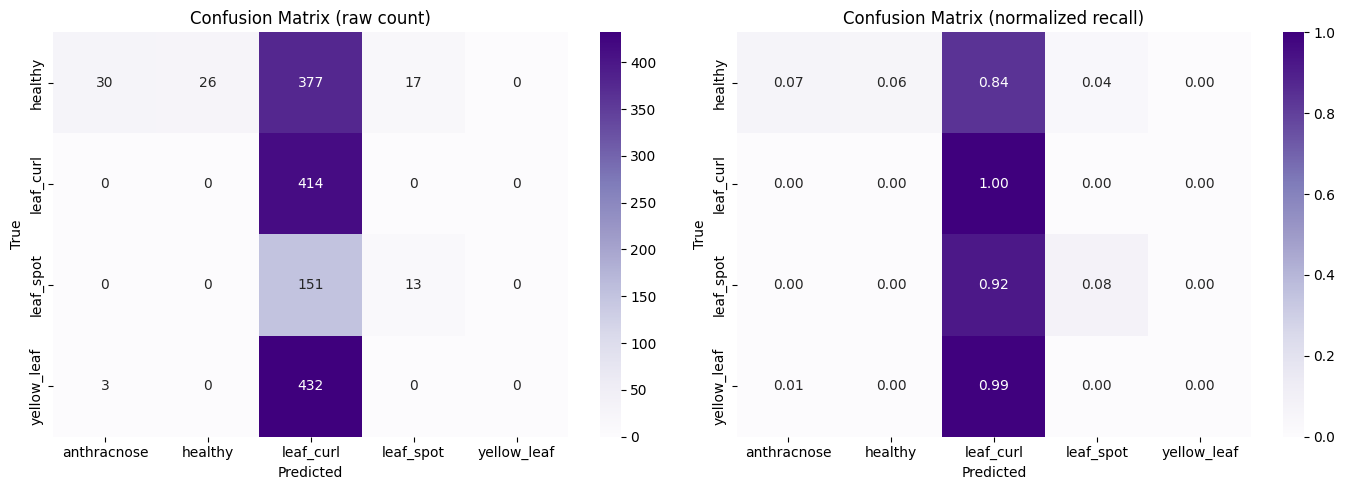

In [18]:
# Tao ma tran tren TOAN BO 5 dau ra de khong lam mat cac du doan nham sang anthracnose,
# sau do chi giu cac hang ground-truth thuc su co trong tap test.
all_class_idx = list(range(len(CLASS_NAMES_TRAIN)))
cm = confusion_matrix(labels_all, preds, labels=all_class_idx)[present_global_idx, :]
_row_sums = cm.sum(axis=1, keepdims=True)
with np.errstate(invalid='ignore', divide='ignore'):
    cm_norm = np.where(_row_sums > 0, cm / _row_sums, 0)

fig, axes = plt.subplots(1, 2, figsize=(2 * max(7, len(CLASS_NAMES_TRAIN)), max(5, len(present_names) - 1)))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=CLASS_NAMES_TRAIN, yticklabels=present_names, ax=axes[0])
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True'); axes[0].set_title('Confusion Matrix (raw count)')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Purples', vmin=0, vmax=1, xticklabels=CLASS_NAMES_TRAIN, yticklabels=present_names, ax=axes[1])
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True'); axes[1].set_title('Confusion Matrix (normalized recall)')

plt.tight_layout()
plt.savefig('cross_dataset_local_cm.png', dpi=300, bbox_inches='tight')
plt.show()